# Лаб. 4. Клітинні автомати для моделювання природничих процесів

Клітинний автомат — це сітка клітин, кожна з яких має один зі скінченної кількості станів. На кожному кроці всі клітини **одночасно** оновлюються за локальним правилом, яке залежить від стану клітини та її сусідів:
- **окіл Мура** — 8 сусідів;
- **окіл фон Неймана** — 4 сусіди (вгору, вниз, ліворуч, праворуч).

Кількість сусідів у певному стані рахуємо для всіх клітин одразу: зсуваємо масив на кожен із векторів окілу й додаємо зсунуті копії.

Межі сітки:
- для «Життя» — **тор**: протилежні краї склеєні, тож фігура, що вийшла праворуч, з'являється ліворуч;
- для лишаю і пожежі — за краєм сітки все дорівнює 0.

In [1]:
import numpy as np; import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from fractions import Fraction
import pandas as pd

MOORE = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
VON_NEUMANN = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def shift(a, dy, dx, wrap = False):
    if wrap:
        return np.roll(a, (dy, dx), axis = (0, 1))
    out = np.zeros_like(a)
    H, W = a.shape
    out[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = \
        a[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return out

def count_neighbors(mask, offsets, wrap = False):
    n = np.zeros(mask.shape, dtype = np.int32)
    for dy, dx in offsets:
        n += shift(mask, dy, dx, wrap)
    return n

## 1. Гра «Життя»

**Стани:** 0 — мертва клітина, 1 — жива. **Окіл:** Мура. Нехай $n$ — кількість живих сусідів. Правило з завдання:
$$s_{t+1} = \begin{cases} 1, & n = 3,\\ s_t, & n = 2,\\ 0, & \text{інакше}. \end{cases}$$

Тобто мертва клітина народжується при 3 живих сусідах, жива виживає при 2 або 3, а в решті випадків клітина гине.

Типи початкових конфігурацій:
- **стаціонарні** — не змінюються: блок, вулик;
- **пульсуючі** — повторюються через $p$ поколінь на тому самому місці: мигалка, жаба, маяк (період 2);
- **рухомі** — повторюються через $p$ поколінь, але зсунутими:
  - планер зсувається на 1 клітину по діагоналі за 4 покоління;
  - легкий космічний корабель (LWSS) зсувається на 2 клітини ліворуч за 4 покоління.

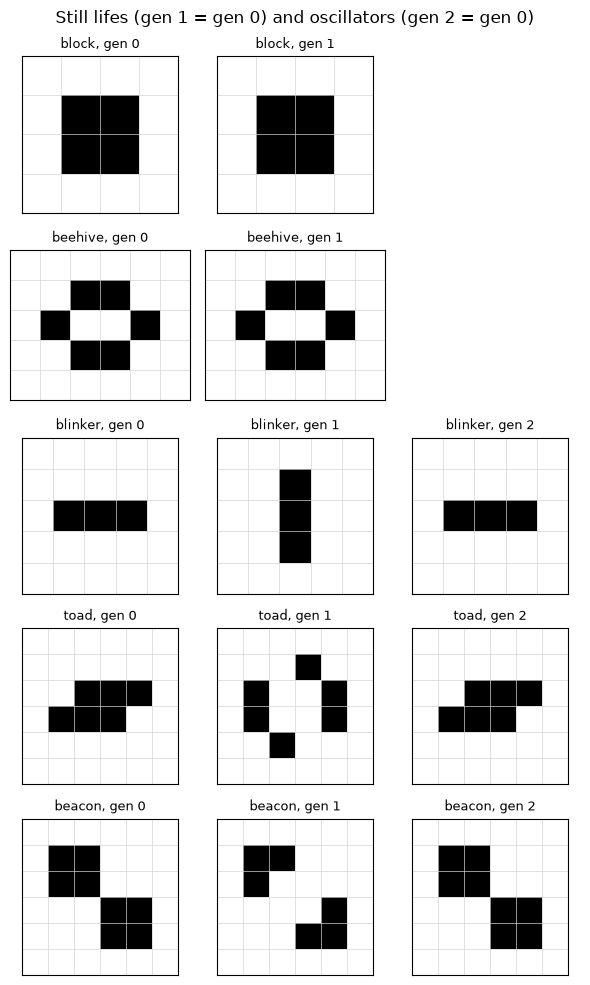

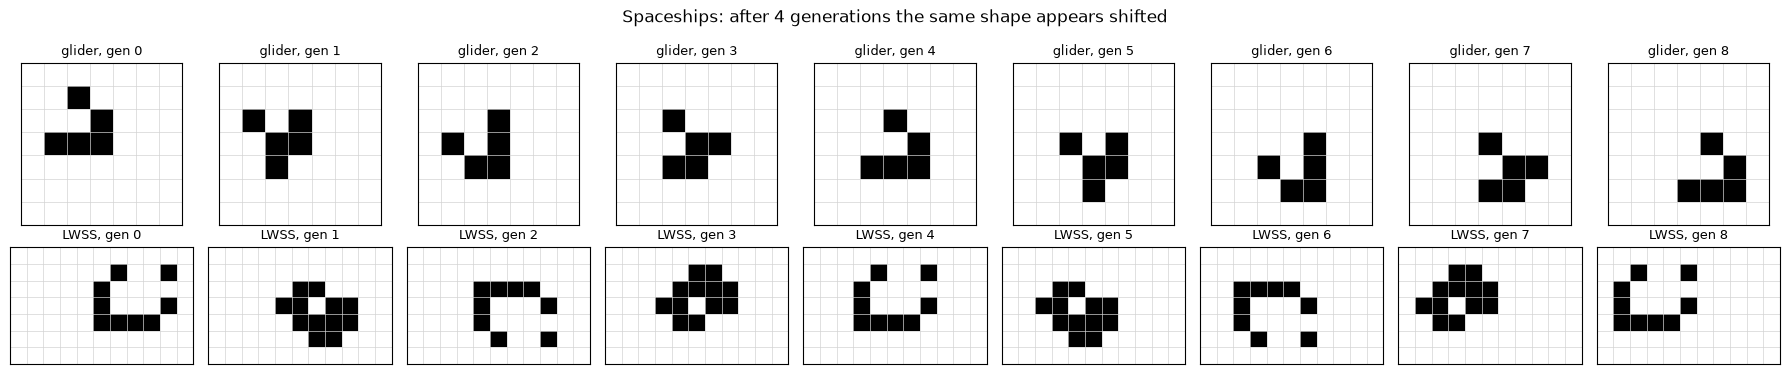

In [2]:
def life_step(g, wrap = True):
    n = count_neighbors(g, MOORE, wrap)
    return np.where(n == 3, 1, np.where(n == 2, g, 0)).astype(np.uint8)

def parse(s):
    return np.array([[c == '#' for c in r.strip()] for r in s.strip().split('\n')], dtype = np.uint8)

PATTERNS = {k: parse(v) for k, v in {
    'block':   '##\n##',
    'beehive': '.##.\n#..#\n.##.',
    'blinker': '###',
    'toad':    '.###\n###.',
    'beacon':  '##..\n##..\n..##\n..##',
    'glider':  '.#.\n..#\n###',
    'LWSS':    '.#..#\n#....\n#...#\n####.',
}.items()}

def draw_cells(ax, g, title = None):
    H, W = g.shape
    ax.imshow(g, cmap = 'Greys', vmin = 0, vmax = 1)
    ax.set_xticks(np.arange(-0.5, W, 1), minor = True)
    ax.set_yticks(np.arange(-0.5, H, 1), minor = True)
    ax.grid(which = 'minor', color = 'lightgray', lw = 0.5)
    ax.set_xticks([]); ax.set_yticks([])
    ax.tick_params(which = 'minor', length = 0)
    if title: ax.set_title(title, fontsize = 9)

def evolve_frames(pat, gens, margin = 8):
    g = np.pad(pat, margin)
    frames = [g]
    for t in range(max(gens)):
        g = life_step(g, wrap = False)
        frames.append(g)
    ys, xs = np.nonzero(np.any([frames[t] for t in gens], axis = 0))
    y0, y1, x0, x1 = ys.min() - 1, ys.max() + 2, xs.min() - 1, xs.max() + 2
    return [frames[t][y0:y1, x0:x1] for t in gens]

def show_rows(rows, title):
    ncol = max(len(g) for _, g in rows)
    fig, axes = plt.subplots(len(rows), ncol, figsize = (2 * ncol, 2 * len(rows)), squeeze = False)
    for r, (name, gens) in enumerate(rows):
        for c, (t, fr) in enumerate(zip(gens, evolve_frames(PATTERNS[name], gens))):
            draw_cells(axes[r, c], fr, f'{name}, gen {t}')
        for c in range(len(gens), ncol):
            axes[r, c].axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_rows([('block', [0, 1]), ('beehive', [0, 1]),
           ('blinker', [0, 1, 2]), ('toad', [0, 1, 2]), ('beacon', [0, 1, 2])],
          'Still lifes (gen 1 = gen 0) and oscillators (gen 2 = gen 0)')
show_rows([('glider', list(range(9))), ('LWSS', list(range(9)))],
          'Spaceships: after 4 generations the same shape appears shifted')

Динаміка поля з усіма прикладами разом:

In [3]:
ZH, ZW = 46, 76
ZOO = [('block', 2, 3), ('beehive', 2, 10), ('blinker', 3, 19), ('toad', 2, 26), ('beacon', 2, 34),
       ('glider', 22, 2), ('LWSS', 34, 70)]
field = np.zeros((ZH, ZW), dtype = np.uint8)
for name, y, x in ZOO:
    p = PATTERNS[name]
    field[y:y + p.shape[0], x:x + p.shape[1]] = p
life_hist = [field]
for t in range(64):
    life_hist.append(life_step(life_hist[-1]))

fig, ax = plt.subplots(figsize = (7.6, 4.8), dpi = 65)
im = ax.imshow(life_hist[0], cmap = 'Greys', vmin = 0, vmax = 1)
ax.set_xticks([]); ax.set_yticks([])

def update(t):
    im.set_data(life_hist[t])
    ax.set_title(f'Life: generation {t}')
    return [im]

anim = FuncAnimation(fig, update, frames = len(life_hist), interval = 150)
plt.close(fig)
HTML(anim.to_jshtml())

## 2. «Стригучий лишай»

Ділянка шкіри має розмір $N\times N$ ($N$ непарне), інфекція починається з центральної клітини. Стан клітини зберігаємо як лічильник $s$:
- $s=0$ — здорова;
- $s=1..6$ — інфікована;
- $s=7..10$ — з імунітетом.

**Правила** (окіл Мура):
1. Кожна інфікована клітина з імовірністю $p$ заражає кожного зі своїх 8 сусідів незалежно від інших. Заразитися може лише здорова клітина, і тоді вона отримує $s=1$.
2. Хворі та імунні клітини «старіють»: $s \to s+1$. Після 6 ітерацій хвороби клітина отримує імунітет ($s=7$), а ще через 4 ітерації ($s=10 \to 0$) знову стає здоровою.

Рахуємо $S(t)$ — здорові, $K(t)$ — інфіковані, $L(t)$ — з імунітетом. Завжди $S+K+L=N^2$.

### Підзавдання: ймовірність ураження центральної клітини

Нехай здорова клітина (центр свого околу $3\times3$) має $k$ уражених сусідів.
- Кожен із них **не** заражає її з імовірністю $1-p$.
- Сусіди діють незалежно, тому ймовірність, що не заразив жоден, дорівнює $(1-p)^k$.
- Клітину уражено, якщо заразив хоча б один сусід. Це протилежна подія:

$$P_k = 1-(1-p)^k, \qquad p=\tfrac12:\quad P_k = 1-\frac{1}{2^k} = \frac{2^k-1}{2^k}.$$

In [4]:
p = Fraction(1, 2)
rows = []
for k in range(9):
    q = (1 - p) ** k
    rows.append({'k': k, '(1-p)^k': f'(1/2)^{k} = {q}', 'P_k = 1-(1-p)^k': f'1 - {q} = {1 - q}', 'P_k': float(1 - q)})
print('p = 1/2')
display(pd.DataFrame(rows).set_index('k'))

table = pd.DataFrame({f'p = {p}': [1 - (1 - p) ** k for k in range(9)] for p in [0.2, 0.35, 0.5, 0.8]})
table.index.name = 'k'
print('P_k for different infection probabilities p')
display(table.round(4))

p = 1/2


,(1-p)^k,P_k = 1-(1-p)^k,P_k
k,,,
0,(1/2)^0 = 1,1 - 1 = 0,0.000000
1,(1/2)^1 = 1/2,1 - 1/2 = 1/2,0.500000
2,(1/2)^2 = 1/4,1 - 1/4 = 3/4,0.750000
3,(1/2)^3 = 1/8,1 - 1/8 = 7/8,0.875000
4,(1/2)^4 = 1/16,1 - 1/16 = 15/16,0.937500
5,(1/2)^5 = 1/32,1 - 1/32 = 31/32,0.968750
6,(1/2)^6 = 1/64,1 - 1/64 = 63/64,0.984375
7,(1/2)^7 = 1/128,1 - 1/128 = 127/128,0.992188
8,(1/2)^8 = 1/256,1 - 1/256 = 255/256,0.996094


P_k for different infection probabilities p


,p = 0.2,p = 0.35,p = 0.5,p = 0.8
k,,,,
0,0.0000,0.0000,0.0000,0.0000
1,0.2000,0.3500,0.5000,0.8000
2,0.3600,0.5775,0.7500,0.9600
3,0.4880,0.7254,0.8750,0.9920
4,0.5904,0.8215,0.9375,0.9984
5,0.6723,0.8840,0.9688,0.9997
6,0.7379,0.9246,0.9844,0.9999
7,0.7903,0.9510,0.9922,1.0000
8,0.8322,0.9681,0.9961,1.0000


### Модель

In [5]:
INF_T, IMM_T = 6, 4
HEALTHY_C, INFECTED_C, IMMUNE_C = '#e3b98f', '#c0392b', '#2e86c1'
RW_CMAP = ListedColormap([HEALTHY_C, INFECTED_C, IMMUNE_C])

def is_infected(g): return (g >= 1) & (g <= INF_T)
def classes(g):     return np.where(g == 0, 0, np.where(g <= INF_T, 1, 2))

def ringworm_step(g, p, rng):
    infected = is_infected(g)
    hit = np.zeros(g.shape, dtype = bool)
    for dy, dx in MOORE:
        hit |= shift(infected & (rng.random(g.shape) < p), dy, dx)
    new = hit & (g == 0)
    out = g.copy()
    out[g > 0] += 1
    out[out > INF_T + IMM_T] = 0
    out[new] = 1
    return out

def run_ringworm(N = 101, p = 0.5, T = 150, seed = None):
    rng = np.random.default_rng(seed)
    g = np.zeros((N, N), dtype = np.int8)
    g[N // 2, N // 2] = 1
    hist = [g]
    for t in range(T):
        hist.append(g := ringworm_step(g, p, rng))
    c = np.array([np.bincount(classes(h).ravel(), minlength = 3) for h in hist])
    return hist, c[:, 0], c[:, 1], c[:, 2]

def draw_skin(ax, g, title):
    ax.imshow(classes(g), cmap = RW_CMAP, vmin = 0, vmax = 2, interpolation = 'nearest')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize = 10)

def plot_SKL(ax, S, K, L, title):
    t = np.arange(len(S))
    ax.plot(t, S, color = HEALTHY_C, lw = 2.2, label = 'S(t) healthy')
    ax.plot(t, K, color = INFECTED_C, lw = 2, label = 'K(t) infected')
    ax.plot(t, L, color = IMMUNE_C, lw = 2, label = 'L(t) immune')
    ax.set_xlabel('t, iterations'); ax.set_ylabel('number of cells'); ax.set_title(title)
    ax.grid(True); ax.legend()

### Результати для різних ймовірностей зараження

$N = 101$. Кольори: бежевий — здорова клітина, червоний — інфікована, синій — з імунітетом.

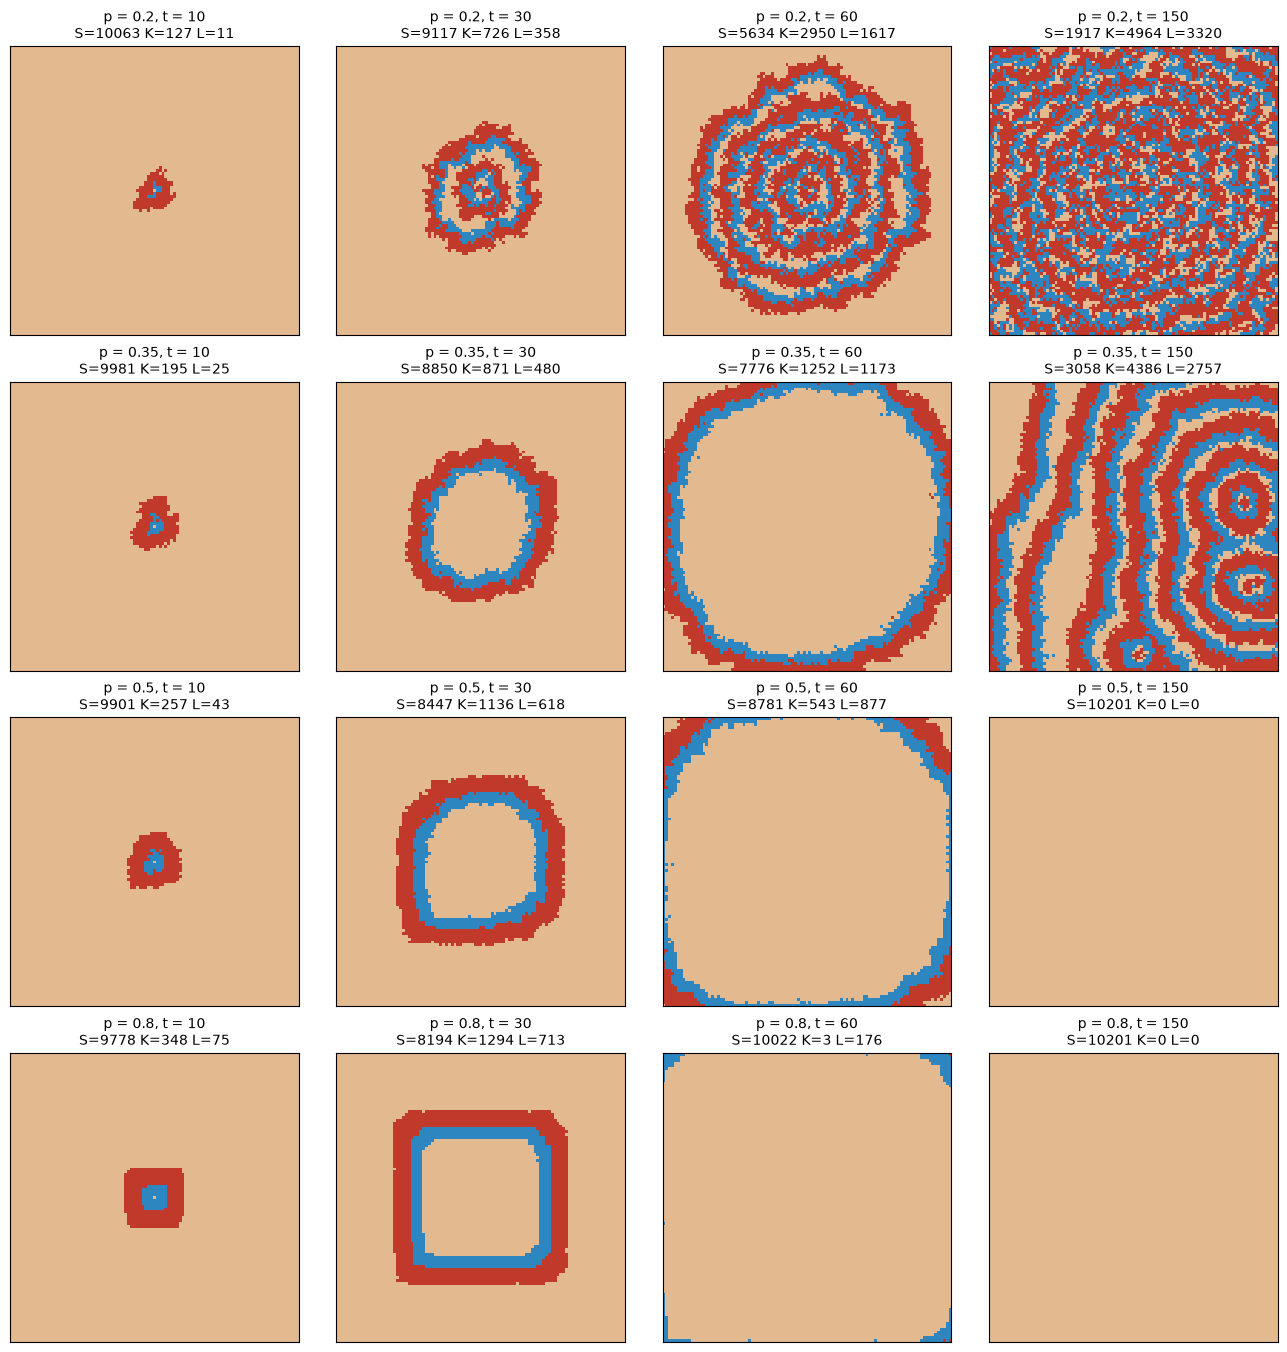

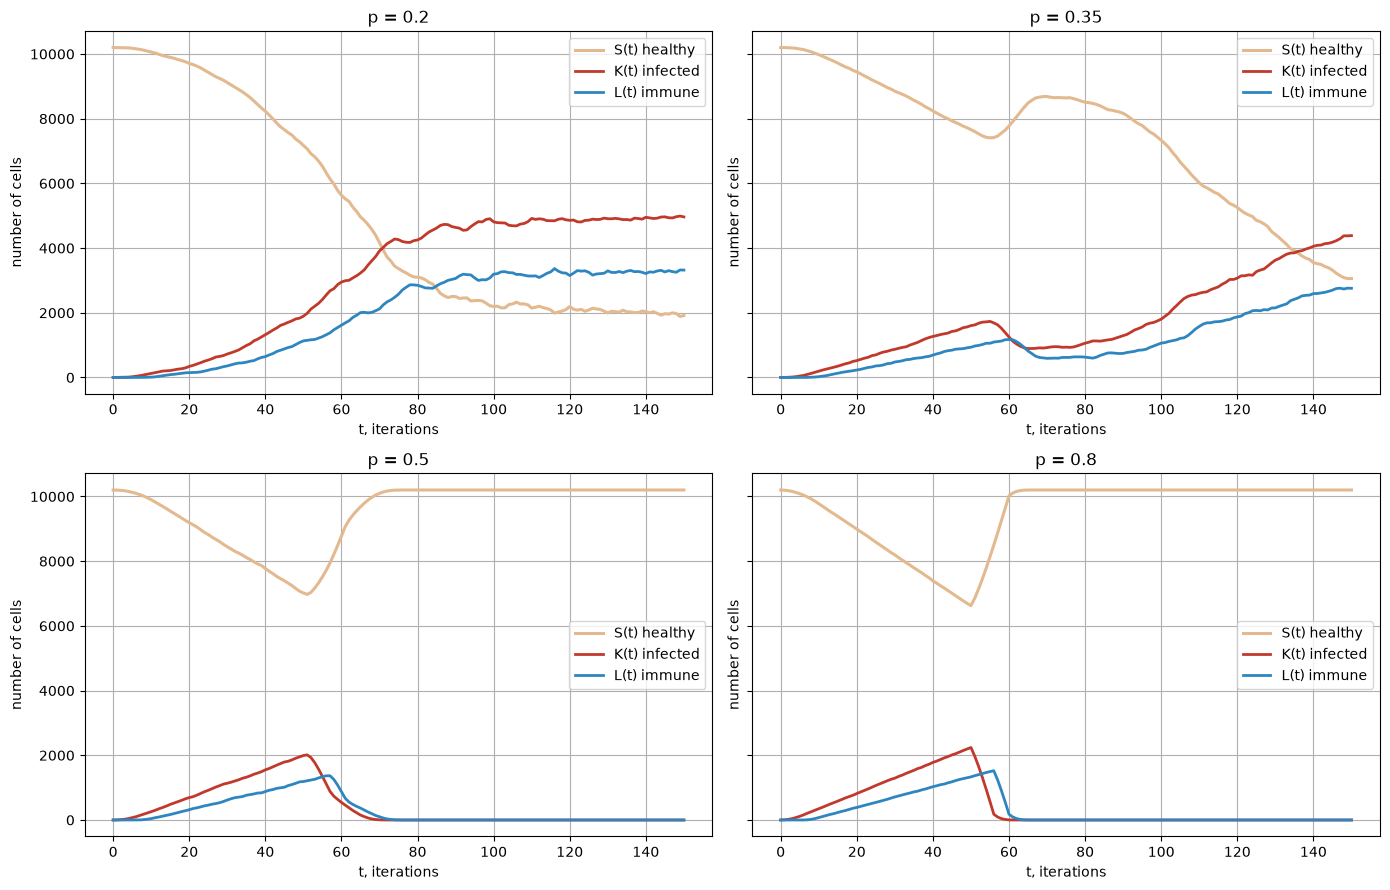

In [6]:
P_SIM = [0.2, 0.35, 0.5, 0.8]
SNAP_T = [10, 30, 60, 150]
runs = {p: run_ringworm(101, p, T = 150, seed = 5) for p in P_SIM}

fig, axes = plt.subplots(len(P_SIM), len(SNAP_T), figsize = (3.3 * len(SNAP_T), 3.4 * len(P_SIM)))
for r, p in enumerate(P_SIM):
    hist_p, S_p, K_p, L_p = runs[p]
    for c, t in enumerate(SNAP_T):
        draw_skin(axes[r, c], hist_p[t], f'p = {p}, t = {t}\nS={S_p[t]} K={K_p[t]} L={L_p[t]}')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize = (14, 9), sharey = True)
for ax, p in zip(axes.flat, P_SIM):
    plot_SKL(ax, *runs[p][1:], f'p = {p}')
plt.tight_layout()
plt.show()

In [7]:
hist, S, K, L = runs[0.5]
fig, ax = plt.subplots(figsize = (5.6, 5.6), dpi = 65)
im = ax.imshow(classes(hist[0]), cmap = RW_CMAP, vmin = 0, vmax = 2, interpolation = 'nearest')
ax.set_xticks([]); ax.set_yticks([])

def update(t):
    im.set_data(classes(hist[t]))
    ax.set_title(f'p = 1/2, t = {t}: K = {K[t]}, L = {L[t]}')
    return [im]

anim = FuncAnimation(fig, update, frames = range(0, 80), interval = 120)
plt.close(fig)
HTML(anim.to_jshtml())

- **$p = 1/2$ і більше.** Від центру розходиться одне кільце: інфікована смуга шириною ≈6 клітин, за нею смуга з імунітетом шириною ≈4, а в центрі шкіра знову здорова. Кільце доходить до краю ділянки й зникає. $K(t)$ і $L(t)$ спочатку зростають лінійно (довжина кільця пропорційна $t$), потім падають до 0.
- **Малі $p$ (0.2, 0.35).** Частина клітин заражається із запізненням і встигає повторно заразити сусідів, що вже одужали. Інфекція не зникає: $K(t)$ виходить на сталий рівень приблизно $N^2/2$.

## 3. Розповсюдження лісової пожежі

**Стани:** 0 — порожньо, 1 — горить, 2 — ліс. **Окіл:** фон Неймана. **Правила:**
1. Ліс загоряється, якщо горить хоча б один із 4 сусідів.
2. Ліс самозаймається (блискавка) з імовірністю $f$.
3. Палаюча клітина стає порожньою.
4. Порожня клітина заростає лісом з імовірністю $p = 0.01$.

Вогонь за крок переходить лише до 4 сусідів, тому фронт пожежі має форму ромба.

In [8]:
EMPTY, FIRE, TREE = 0, 1, 2
FOREST_CMAP = ListedColormap(['black', 'red', 'limegreen'])
P_GROW = 0.01

def forest_step(g, p, f, rng):
    fire, tree, empty = g == FIRE, g == TREE, g == EMPTY
    fire_near = count_neighbors(fire, VON_NEUMANN) > 0
    xi = rng.random(g.shape)
    out = g.copy()
    out[fire] = EMPTY
    out[tree & (fire_near | (xi < f))] = FIRE
    out[empty & (xi < p)] = TREE
    return out

def run_forest(f, L = 100, p = P_GROW, T = 3000, seed = None):
    rng = np.random.default_rng(seed)
    g = np.where(rng.random((L, L)) < 0.5, TREE, EMPTY).astype(np.int8)
    hist = [g]
    for t in range(T):
        hist.append(g := forest_step(g, p, f, rng))
    return hist

def draw_forest(ax, g, title):
    ax.imshow(g, cmap = FOREST_CMAP, vmin = 0, vmax = 2, interpolation = 'nearest')
    ax.set_title(title, fontsize = 10)

### Результати для різних ймовірностей початку горіння $f$

Сітка $100\times100$, початково ліс з густиною 0.5, $p = 0.01$, 3000 кроків.

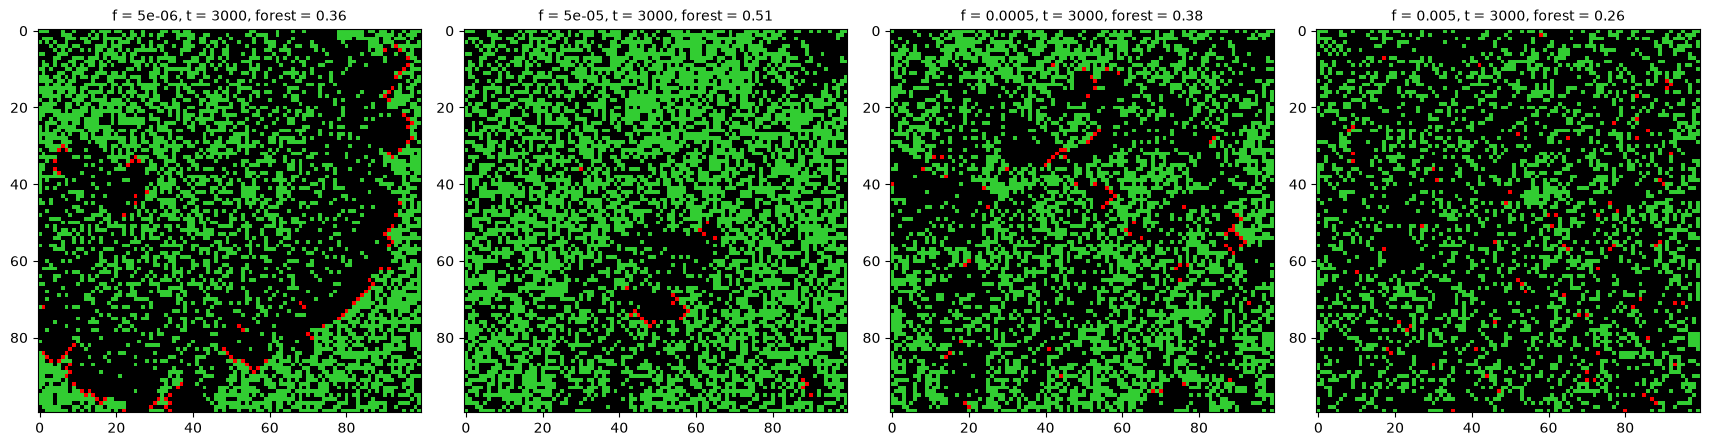

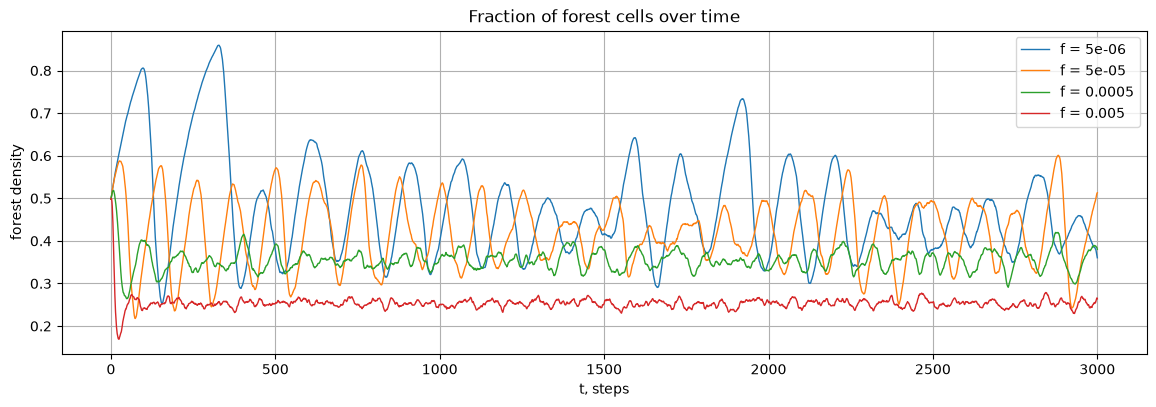

In [9]:
F_LIST = [5e-6, 5e-5, 5e-4, 5e-3]
fruns = {f: run_forest(f, seed = 7) for f in F_LIST}

fig, axes = plt.subplots(1, len(F_LIST), figsize = (4.3 * len(F_LIST), 4.3))
for ax, f in zip(axes, F_LIST):
    g = fruns[f][-1]
    draw_forest(ax, g, f'f = {f}, t = 3000, forest = {(g == TREE).mean():.2f}')
plt.tight_layout()
plt.show()

plt.figure(figsize = (14, 4.2))
for f in F_LIST:
    plt.plot([(h == TREE).mean() for h in fruns[f]], lw = 1, label = f'f = {f}')
plt.xlabel('t, steps'); plt.ylabel('forest density'); plt.grid(True); plt.legend()
plt.title('Fraction of forest cells over time')
plt.show()

In [10]:
hist = fruns[5e-6]
burning = np.array([(h == FIRE).sum() for h in hist])
t_peak = 500 + np.argmax(burning[500:])

fig, ax = plt.subplots(figsize = (5.4, 5.4), dpi = 65)
im = ax.imshow(hist[0], cmap = FOREST_CMAP, vmin = 0, vmax = 2, interpolation = 'nearest')

def update(t):
    im.set_data(hist[t])
    ax.set_title(f'forest fire, f = 5e-6, t = {t}')
    return [im]

anim = FuncAnimation(fig, update, frames = range(t_peak - 60, t_peak + 140, 2), interval = 100)
plt.close(fig)
HTML(anim.to_jshtml())

- **$f = 5\cdot10^{-6}$ (з умови).** Блискавки рідкісні, тому між пожежами ліс встигає густо зарости. Кожна пожежа величезна: ромбоподібні фронти проходять майже весь ліс, а густина лісу сильно коливається.
- **Більше $f$.** Пожежі частіші, але менші: ліс не встигає зарости, середня густина лісу нижча, а коливання слабші.

## Висновки

1. **«Життя».** Реалізовано правило з умови. Показано конфігурації:
   - стаціонарні — блок, вулик;
   - пульсуючі — мигалка, жаба, маяк з періодом 2;
   - рухомі — планер і LWSS, які повторюють форму через 4 покоління зі зсувом.
2. **«Стригучий лишай».**
   - Ймовірність ураження клітини з $k$ ураженими сусідами $P_k = 1-(1-p)^k$; для $p = 1/2$ це $(2^k-1)/2^k$.
   - При $p \ge 1/2$ інфекція проходить одним кільцем і зникає.
   - При малих $p$ інфекція лишається на шкірі постійно.
3. **Лісова пожежа.** Чим менша ймовірність самозаймання $f$, тим рідші, але більші пожежі й тим сильніше коливається густина лісу.